In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

from src.data import load_table, to_binary, split_xy
from src.features import build_preprocessor
from src.models import get_models, fit_all
from src.evaluate import compare, cutoff_table


ImportError: DLL load failed while importing _gufuncs: An Application Control policy has blocked this file.

In [ ]:
train = load_table("../data/KDDTrain.parquet")
test  = load_table("../data/KDDTest.parquet")

X_train, labels_train = split_xy(train, "class", extra_drop=["classnum"])
X_test,  labels_test  = split_xy(test,  "class", extra_drop=['classnum'])
y_train = to_binary(labels_train, "normal")
y_test  = to_binary(labels_test,  "normal")

preprocessor, cat_cols, num_cols = build_preprocessor(X_train)
print(len(cat_cols), "categorical,", len(num_cols), "numeric")


3 categorical, 33 numeric


In [ ]:
fitted = fit_all(get_models(), preprocessor, X_train, y_train)
compare(fitted, X_test, y_test)

,model,accuracy,attack_precision,attack_recall,attack_f1,missed_attacks,false_alarms
0,Random Forest,0.790,0.969,0.652,0.779,4469,266
1,Logistic Regression,0.752,0.916,0.621,0.740,4863,734
2,XGBoost,0.794,0.968,0.660,0.785,4368,282


In [ ]:
proba = fitted["Random Forest"].predict_proba(X_test)[:, 1]
cutoff_table("RF", y_test, proba)

,model,accuracy,attack_precision,attack_recall,attack_f1,missed_attacks,false_alarms
0,RF @ 0.5,0.792,0.969,0.655,0.782,4421,266
1,RF @ 0.2,0.851,0.924,0.805,0.860,2498,856
2,RF @ 0.1,0.894,0.923,0.887,0.905,1452,948
3,RF @ 0.05,0.911,0.920,0.924,0.922,969,1037


In [ ]:
import shap
print(shap.__version__)

c:\Intro detection\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0.54.1


In [ ]:
import numpy as np
import shap

rf = fitted["Random Forest"]
prep = rf.named_steps["prep"]
clf = rf.named_steps["clf"]

rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), size=500, replace=False)
Xs = prep.transform(X_test.iloc[idx])
if hasattr(Xs, "toarray"):
    Xs = Xs.toarray()
name = prep.get_feature_names_out()

explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xs)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]
print(sv.shape, Xs.shape)

(500, 117) (500, 117)


In [ ]:
pos = np.where(y_test.iloc[idx].values == 1)[0][0]
row = X_test.iloc[idx].iloc[pos]
print("true label:", labels_test.iloc[idx].iloc[pos])
print(row[["flag", "service", "src_bytes", "dst_bytes", "serror_rate"]])
for i in np.argsort(-np.abs(sv[pos]))[:8]:
    print(f"{name[i]:35s} {sv[pos][i]:+.3f}")

true label: neptune
flag             S0
service        ldap
src_bytes         0
dst_bytes         0
serror_rate     1.0
Name: 20425, dtype: object
num__src_bytes                      +0.096
cat__flag_SF                        +0.067
num__dst_host_srv_serror_rate       +0.066
num__dst_bytes                      +0.054
num__serror_rate                    +0.049
num__same_srv_rate                  +0.040
num__dst_host_same_srv_rate         +0.036
cat__flag_S0                        +0.031


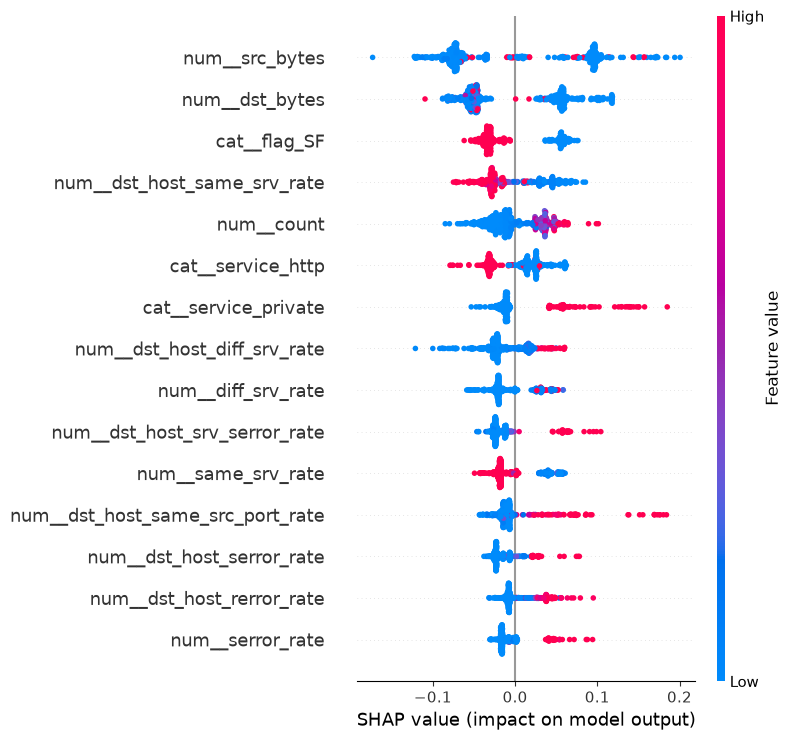

In [ ]:
shap.summary_plot(sv, Xs, feature_names=name, max_display=15)

In [ ]:
neg = np.where(y_test.iloc[idx].values == 0)[0][0]
for i in np.argsort(-np.abs(sv[neg]))[:8]:
    print(f"{name[i]:35s} {sv[neg][i]:+.3f}")

num__src_bytes                      -0.074
num__dst_bytes                      -0.051
cat__flag_SF                        -0.033
cat__service_http                   -0.033
num__dst_host_same_srv_rate         -0.030
num__dst_host_srv_serror_rate       -0.026
num__dst_host_diff_srv_rate         -0.025
num__dst_host_serror_rate           -0.023


In [ ]:
mb = np.where(labels_test.astype(str).values == "mailbomb")[0][:100]
Xm = prep.transform(X_test.iloc[mb])
if hasattr(Xm, "toarray"):
    Xm = Xm.toarray()
svm = explainer.shap_values(Xm)
if isinstance(svm, list):
    svm = svm[1]
elif svm.ndim == 3:
    svm = svm[:, :, 1]
print("mean attack probability:", clf.predict_proba(Xm)[:, 1].mean(),round(3))
for i in np.argsort(-np.abs(svm).mean(axis=0))[:8]:
    print(f"{name[i]:35s} {svm[:, i].mean():+.3f}")

mean attack probability: 0.045100000000000015 3
num__src_bytes                      -0.091
num__dst_bytes                      -0.075
cat__flag_SF                        -0.043
num__dst_host_rerror_rate           +0.031
num__dst_host_same_srv_rate         -0.019
num__dst_host_srv_serror_rate       -0.025
num__diff_srv_rate                  -0.015
num__dst_host_serror_rate           -0.022


In [ ]:
ev = np.ravel(explainer.expected_value)[-1]
p = clf.predict_proba(Xs[neg:neg+1])[0,1]
print("baseline + contributions:", round(ev + sv[neg].sum(), 3))
print("model probability:"       , round(p, 3))

baseline + contributions: -0.0
model probability: 0.0


In [ ]:
print("mean attack probability:", clf.predict_proba(Xm)[:, 1].mean().round(3))

mean attack probability: 0.045


In [ ]:
mb = np.where(labels_test.astype(str).values == "mailbomb")[0]

In [ ]:
mb = np.where(labels_test.astype(str).values == "mailbomb")[0]
print("mailbomb rows:", len(mb))

Xm = prep.transform(X_test.iloc[mb])
if hasattr(Xm, "toarray"):
    Xm = Xm.toarray()

svm = explainer.shap_values(Xm)
if isinstance(svm, list):
    svm = svm[1]
elif svm.ndim == 3:
    svm = svm[:, :, 1]

print("mean attack probability:", clf.predict_proba(Xm)[:, 1].mean().round(3))
for i in np.argsort(-np.abs(svm).mean(axis=0))[:8]:
    print(f"{name[i]:35s} {svm[:, i].mean():+.3f}")

mailbomb rows: 293
mean attack probability: 0.046
num__src_bytes                      -0.092
num__dst_bytes                      -0.076
cat__flag_SF                        -0.043
num__dst_host_rerror_rate           +0.033
num__dst_host_same_srv_rate         -0.019
num__dst_host_srv_serror_rate       -0.025
num__diff_srv_rate                  -0.015
num__dst_host_serror_rate           -0.022


SHAP add, mailbomb = 0.0046


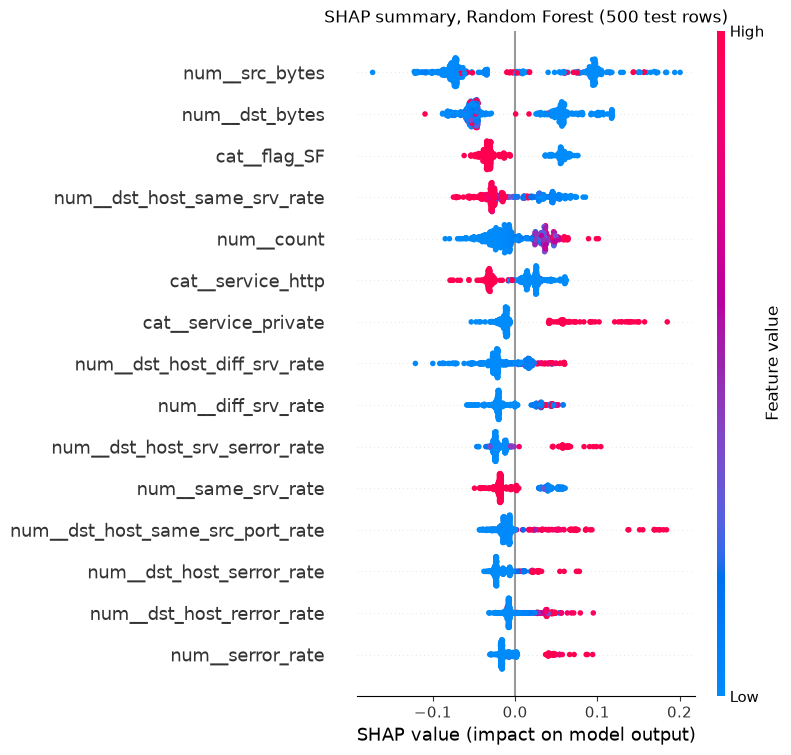

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("../images", exist_ok=True)
shap.summary_plot(sv, Xs, feature_names=name, max_display=15, show=False)
plt.title("SHAP summary, Random Forest (500 test rows)")
plt.savefig("../images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## What the model relies on (SHAP, Random Forest, 500 test rows)

- The strongest signals are SYN-error rates, whether the connection completed normally (`flag_SF`), and byte counts. A `neptune` (SYN flood) row had flag `S0`, `serror_rate` 1.0 and zero bytes, and every top feature pushed it toward "attack". A normal row showed the same features pushing the other way.
- `service_private` pushes strongly toward "attack" and `service_http` toward "normal". This may be a quirk of how the dataset was built (untested), so I treat it as a possible shortcut.
- All 293 `mailbomb` rows get a mean attack probability of 0.046. Their byte counts and completed connections push toward "normal", which fits why a lower cutoff cannot recover them.
- SHAP explains the model, not the real world: these are patterns the model uses, not proof about the attacks.

In [ ]:
import streamlit

In [2]:
import joblib, os

os.makedirs("../models", exist_ok=True)
for model_name, pipe in fitted.items():
    path = f"../models/{model_name.replace(' ', '_').lower()}.joblib"
    joblib.dump(pipe, path, compress=3)
    print(path, round(os.path.getsize(path) / 1e6, 1), "MB")

NameError: name 'fitted' is not defined

In [3]:
import sys
print(sys.executable)


c:\Intro detection\venv\Scripts\python.exe
